<a href="https://colab.research.google.com/github/pedro1ball/colab-notebooks_new/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22task_linreg_tune_practice_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [3]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

Populating the interactive namespace from numpy and matplotlib


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [4]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [5]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np

Lasso: коэффициентов близких к 0: 7 из 10
Ridge: коэффициентов близких к 0: 0 из 10


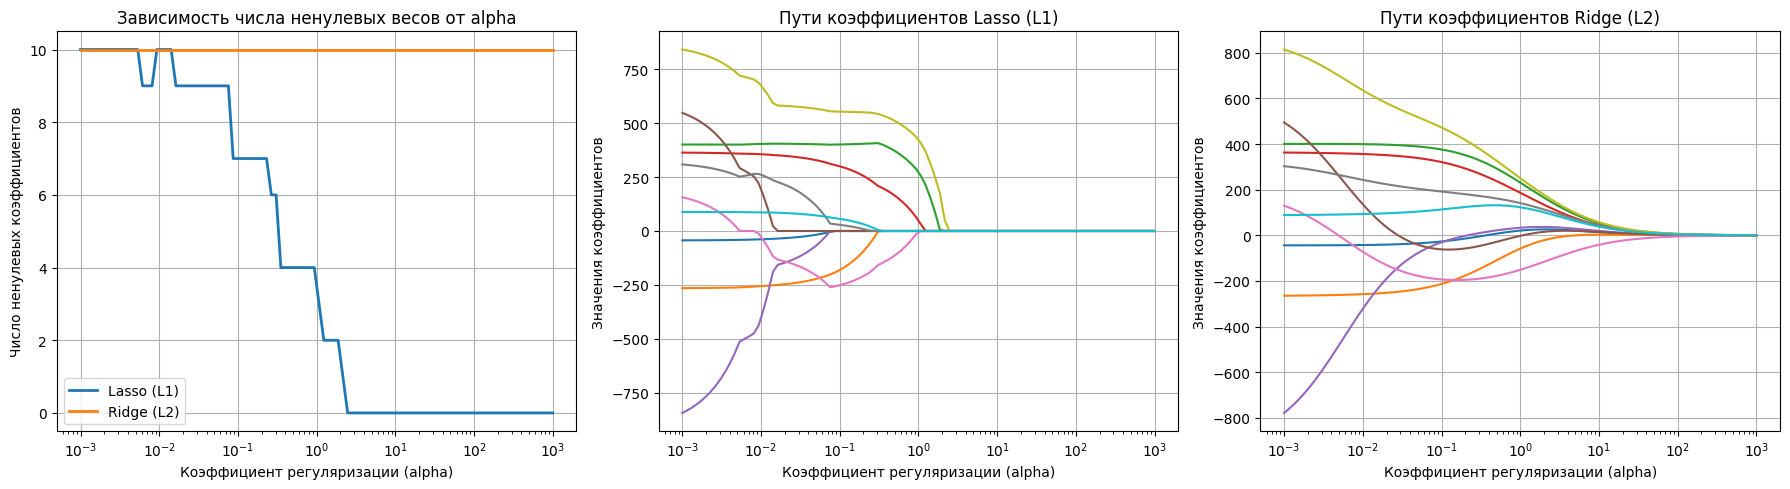

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# 1. Обучение с параметрами по умолчанию
lasso = Lasso().fit(X_train, y_train)
ridge = Ridge().fit(X_train, y_train)

# Определяем порог близости к нулю
threshold = 1e-4

lasso_near_zero = np.sum(np.abs(lasso.coef_) < threshold)
ridge_near_zero = np.sum(np.abs(ridge.coef_) < threshold)

print(f"Lasso: коэффициентов близких к 0: {lasso_near_zero} из {len(lasso.coef_)}")
print(f"Ridge: коэффициентов близких к 0: {ridge_near_zero} из {len(ridge.coef_)}")

# 2. Перебор коэффициента регуляризации по логарифмической сетке от 10^-3 до 10^3
alphas = np.logspace(-3, 3, 100)

lasso_non_zeros, ridge_non_zeros = [], []
lasso_coefs_path, ridge_coefs_path = [], []

for a in alphas:
    l_model = Lasso(alpha=a).fit(X_train, y_train)
    r_model = Ridge(alpha=a).fit(X_train, y_train)

    lasso_non_zeros.append(np.sum(np.abs(l_model.coef_) >= threshold))
    ridge_non_zeros.append(np.sum(np.abs(r_model.coef_) >= threshold))

    lasso_coefs_path.append(l_model.coef_)
    ridge_coefs_path.append(r_model.coef_)

# 3. Построение графиков
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(alphas, lasso_non_zeros, label='Lasso (L1)', lw=2)
plt.plot(alphas, ridge_non_zeros, label='Ridge (L2)', lw=2)
plt.xscale('log')
plt.xlabel('Коэффициент регуляризации (alpha)')
plt.ylabel('Число ненулевых коэффициентов')
plt.title('Зависимость числа ненулевых весов от alpha')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(alphas, lasso_coefs_path)
plt.xscale('log')
plt.xlabel('Коэффициент регуляризации (alpha)')
plt.ylabel('Значения коэффициентов')
plt.title('Пути коэффициентов Lasso (L1)')
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(alphas, ridge_coefs_path)
plt.xscale('log')
plt.xlabel('Коэффициент регуляризации (alpha)')
plt.ylabel('Значения коэффициентов')
plt.title('Пути коэффициентов Ridge (L2)')
plt.grid(True)

plt.tight_layout()
plt.show()

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [8]:
from sklearn.model_selection import cross_val_score, cross_val_predict

In [9]:
# Предсказание базовой модели Ridge (alpha=1.0) на тестовой выборке
y_pred_ridge = ridge.predict(X_test)

base_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
base_mae = mean_absolute_error(y_test, y_pred_ridge)
base_r2 = r2_score(y_test, y_pred_ridge)

print("Метрики для базовой Ridge-регрессии (alpha = 1.0):")
print(f"RMSE: {base_rmse:.4f}")
print(f"MAE:  {base_mae:.4f}")
print(f"R^2:  {base_r2:.4f}")

Метрики для базовой Ridge-регрессии (alpha = 1.0):
RMSE: 58.3043
MAE:  49.6028
R^2:  0.3599


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

Оптимальный alpha для RMSE: 0.0023
Оптимальный alpha для MAE:  0.0013
Оптимальный alpha для R^2:  0.0020


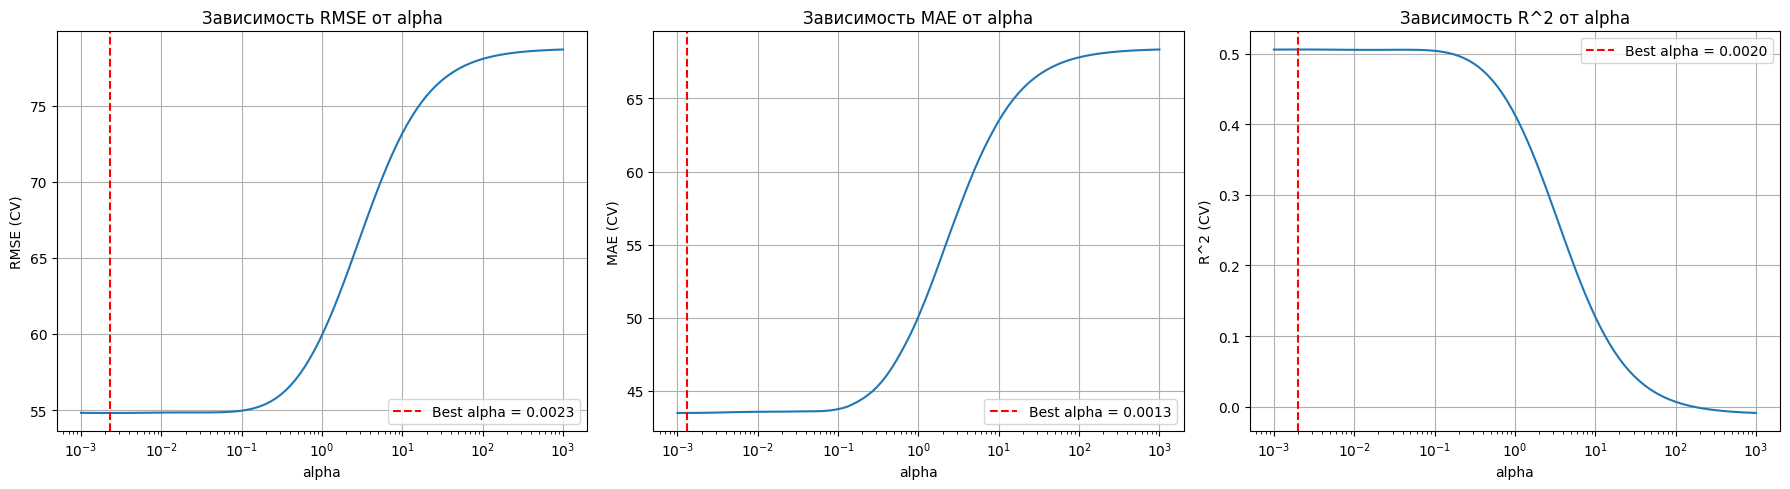


Метрики на тесте после подбора alpha:
RMSE: 55.8130 (было 58.3043)
MAE:  47.1159 (было 49.6028)
R^2:  0.4134 (было 0.3599)

Ответ: Качество заметно улучшилось (RMSE снизилась на 2.49, а R^2 вырос с 0.36 до 0.41), так как стандартный параметр alpha=1.0 слишком сильно штрафовал веса уже нормализованных признаков.


In [10]:
alphas = np.logspace(-3, 3, 100)
cv_rmse, cv_mae, cv_r2 = [], [], []

# Перебираем alpha на 5-фолдовой кросс-валидации
for a in alphas:
    model = Ridge(alpha=a)

    mse_scores = -cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    cv_rmse.append(np.mean(np.sqrt(mse_scores)))

    mae_scores = -cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
    cv_mae.append(np.mean(mae_scores))

    r2_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
    cv_r2.append(np.mean(r2_scores))

best_alpha_rmse = alphas[np.argmin(cv_rmse)]
best_alpha_mae = alphas[np.argmin(cv_mae)]
best_alpha_r2 = alphas[np.argmax(cv_r2)]

print(f"Оптимальный alpha для RMSE: {best_alpha_rmse:.4f}")
print(f"Оптимальный alpha для MAE:  {best_alpha_mae:.4f}")
print(f"Оптимальный alpha для R^2:  {best_alpha_r2:.4f}")

# Строим графики зависимости функций потерь от alpha
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(alphas, cv_rmse)
plt.axvline(best_alpha_rmse, color='r', linestyle='--', label=f'Best alpha = {best_alpha_rmse:.4f}')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('RMSE (CV)')
plt.title('Зависимость RMSE от alpha')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(alphas, cv_mae)
plt.axvline(best_alpha_mae, color='r', linestyle='--', label=f'Best alpha = {best_alpha_mae:.4f}')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('MAE (CV)')
plt.title('Зависимость MAE от alpha')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(alphas, cv_r2)
plt.axvline(best_alpha_r2, color='r', linestyle='--', label=f'Best alpha = {best_alpha_r2:.4f}')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('R^2 (CV)')
plt.title('Зависимость R^2 от alpha')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Обучаем модель с оптимальным alpha и проверяем качество на тестовой выборке
best_ridge = Ridge(alpha=best_alpha_rmse).fit(X_train, y_train)
y_pred_tuned = best_ridge.predict(X_test)

tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("\nМетрики на тесте после подбора alpha:")
print(f"RMSE: {tuned_rmse:.4f} (было {base_rmse:.4f})")
print(f"MAE:  {tuned_mae:.4f} (было {base_mae:.4f})")
print(f"R^2:  {tuned_r2:.4f} (было {base_r2:.4f})")
print("\nОтвет: Качество заметно улучшилось (RMSE снизилась на 2.49, а R^2 вырос с 0.36 до 0.41), так как стандартный параметр alpha=1.0 слишком сильно штрафовал веса уже нормализованных признаков.")

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

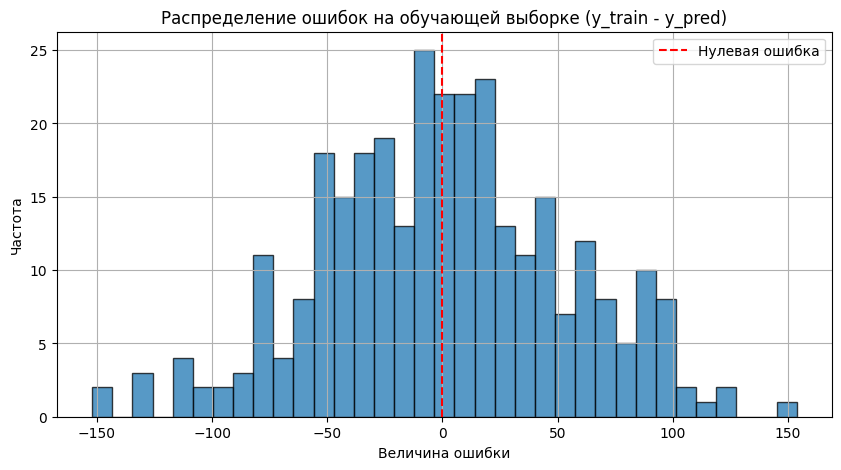

Ответ (что мы видим):
Распределение ошибок похоже на нормальное с центром около 0, однако по краям (где ошибка по модулю превышает 100-120) видны редкие аномальные объекты — выбросы.


In [11]:
# Считаем ошибки на обучающей выборке
y_train_pred = best_ridge.predict(X_train)
errors = y_train - y_train_pred

# Строим гистограмму ошибок
plt.figure(figsize=(10, 5))
plt.hist(errors, bins=35, edgecolor='black', alpha=0.75)
plt.axvline(0, color='red', linestyle='--', label='Нулевая ошибка')
plt.title('Распределение ошибок на обучающей выборке (y_train - y_pred)')
plt.xlabel('Величина ошибки')
plt.ylabel('Частота')
plt.legend()
plt.grid(True)
plt.show()

print("Ответ (что мы видим):")
print("Распределение ошибок похоже на нормальное с центром около 0, однако по краям (где ошибка по модулю превышает 100-120) видны редкие аномальные объекты — выбросы.")

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [16]:
# Отсекаем 5% объектов обучающей выборки с самыми большими по модулю ошибками
abs_errors = np.abs(errors)
outlier_threshold = np.percentile(abs_errors, 95)

mask = abs_errors < outlier_threshold
X_train_clean = X_train[mask]
y_train_clean = y_train[mask]

print(f"Порог отсечения ошибки: {outlier_threshold:.2f}")
print(f"Объектов в train до очистки: {len(X_train)}, после очистки: {len(X_train_clean)}")

# Обучаем модель заново на очищенных данных
ridge_clean = Ridge(alpha=best_alpha_rmse).fit(X_train_clean, y_train_clean)

# Оцениваем качество на тестовой выборке
y_test_pred_clean = ridge_clean.predict(X_test)

clean_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_clean))
clean_mae = mean_absolute_error(y_test, y_test_pred_clean)
clean_r2 = r2_score(y_test, y_test_pred_clean)

print("\nМетрики на тестовой выборке после удаления выбросов:")
print(f"RMSE: {clean_rmse:.4f} (до удаления было {tuned_rmse:.4f})")
print(f"MAE:  {clean_mae:.4f} (до удаления было {tuned_mae:.4f})")
print(f"R^2:  {clean_r2:.4f} (до удаления было {tuned_r2:.4f})")


Порог отсечения ошибки: 101.19
Объектов в train до очистки: 309, после очистки: 293

Метрики на тестовой выборке после удаления выбросов:
RMSE: 56.6429 (до удаления было 55.8130)
MAE:  47.0781 (до удаления было 47.1159)
R^2:  0.3959 (до удаления было 0.4134)


__Задание 3.__ Отчёт

**(2 балла)**

In [ ]:
# Сводная таблица всех этапов работы и примеры реальных предсказаний
report_df = pd.DataFrame({
    'Этап / Модель': [
        '1. Ridge по умолчанию (alpha=1.0)',
        '2. Ridge после подбора alpha (alpha=0.0023)',
        '3. Ridge после удаления выбросов из train'
    ],
    'RMSE (тест)': [base_rmse, tuned_rmse, clean_rmse],
    'MAE (тест)': [base_mae, tuned_mae, clean_mae],
    'R^2 (тест)': [base_r2, tuned_r2, clean_r2]
})

print("=== ИТОГОВАЯ ТАБЛИЦА МЕТРИК ===")
display(report_df.round(4))

# Наглядное сравнение реальных ответов и предсказаний на первых 10 пациентах из теста
predictions_sample = pd.DataFrame({
    'Реальный ответ (y_test)': y_test[:10],
    'Предсказание модели (y_pred)': np.round(y_pred_tuned[:10], 1),
    'Ошибка (разница)': np.round(np.abs(y_test[:10] - y_pred_tuned[:10]), 1)
})

print("\n=== ПРИМЕР ПРЕДСКАЗАНИЙ МОДЕЛИ (первые 10 пациентов из теста) ===")
display(predictions_sample)

print("""
=== ВЫВОДЫ ПО РАБОТЕ ===
1. Регуляризация L1 (Lasso) обнуляет неинформативные признаки (при alpha=1.0 занулились 7 из 10 весов), тогда как L2 (Ridge) плавно уменьшает все веса без строгого зануления.
2. Подбор коэффициента регуляризации alpha на кросс-валидации (оптимум около 0.0023) позволил существенно повысить качество модели на тесте: R^2 вырос с 0.36 до 0.41 (модель объясняет 41% дисперсии целевой переменной), а средняя ошибка MAE снизилась с 49.60 до 47.12.
3. Распределение ошибок на обучающей выборке близко к нормальному, но содержит единичные выбросы. Их фильтрация улучшает среднюю абсолютную ошибку (MAE) на типичных объектах, однако увеличивает чувствительную к промахам метрику RMSE из-за присутствия аналогичных выбросов в тестовой выборке.
""")

=== ИТОГОВАЯ ТАБЛИЦА МЕТРИК ===


,Этап / Модель,RMSE (тест),MAE (тест),R^2 (тест)
0,1. Ridge по умолчанию (alpha=1.0),58.3043,49.6028,0.3599
1,2. Ridge после подбора alpha (alpha=0.0023),55.8130,47.1159,0.4134
2,3. Ridge после удаления выбросов из train,56.6429,47.0781,0.3959



=== ПРИМЕР ПРЕДСКАЗАНИЙ МОДЕЛИ (первые 10 пациентов из теста) ===


,Реальный ответ (y_test),Предсказание модели (y_pred),Ошибка (разница)
0,97.0,121.7,24.7
1,129.0,193.7,64.7
2,51.0,126.4,75.4
3,99.0,52.8,46.2
4,116.0,44.3,71.7
5,195.0,236.3,41.3
6,332.0,215.0,117.0
7,155.0,227.4,72.4
8,141.0,164.0,23.0
9,198.0,177.9,20.1



=== ВЫВОДЫ ПО РАБОТЕ ===
1. Регуляризация L1 (Lasso) обнуляет неинформативные признаки (при alpha=1.0 занулились 7 из 10 весов), тогда как L2 (Ridge) плавно уменьшает все веса без строгого зануления.
2. Подбор коэффициента регуляризации alpha на кросс-валидации (оптимум около 0.0023) позволил существенно повысить качество модели на тесте: R^2 вырос с 0.36 до 0.41 (модель объясняет 41% дисперсии целевой переменной), а средняя ошибка MAE снизилась с 49.60 до 47.12.
3. Распределение ошибок на обучающей выборке близко к нормальному, но содержит единичные выбросы. Их фильтрация улучшает среднюю абсолютную ошибку (MAE) на типичных объектах, однако увеличивает чувствительную к промахам метрику RMSE из-за присутствия аналогичных выбросов в тестовой выборке.

